#RFM Data Analysis & Visualization

**Project:** Customer Segmentation Using RFM Analysis  
**Dataset:** Synthetic e-commerce data generated for this project  
**Database output:** SQL result CSVs

## Objective
Explore customer recency, frequency, monetary value, segment distribution, revenue patterns, product categories and acquisition channels. This notebook performs **descriptive analysis only**; it does not train a predictive model.

**RFM definitions used:**
- **Recency:** days between the reference date (1 November 2026) and the customer's latest completed purchase. Lower is better.
- **Frequency:** number of distinct completed invoice IDs.
- **Monetary:** sum of net purchase value from completed transactions, after discount.
- Cancelled and returned transactions are excluded from RFM.


In [19]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

# Find the project root whether this notebook is run from VS Code or Jupyter
CURRENT = Path.cwd()
if (CURRENT / "outputs" / "sql_results").exists():
    PROJECT_ROOT = CURRENT
elif (CURRENT.parent / "outputs" / "sql_results").exists():
    PROJECT_ROOT = CURRENT.parent
else:
    raise FileNotFoundError("Could not find outputs/sql_results. Keep this notebook inside the project's notebooks folder.")

RESULTS = PROJECT_ROOT / "outputs" / "sql_results"
CHARTS = PROJECT_ROOT / "outputs" / "p9_charts"
CHARTS.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Chart output folder:", CHARTS)

Project folder: C:\Users\Priyanshu\Desktop\hcl\Project
Chart output folder: C:\Users\Priyanshu\Desktop\hcl\Project\outputs\p9_charts


In [20]:
rfm = pd.read_csv(RESULTS / "q1_customer_rfm_segments.csv")
segment_counts = pd.read_csv(RESULTS / "q2_customer_segment_distribution.csv")
top10 = pd.read_csv(RESULTS / "q3_top_10_customers_by_monetary.csv")
category = pd.read_csv(RESULTS / "q4_revenue_by_product_category.csv")
monthly = pd.read_csv(RESULTS / "q5_monthly_revenue.csv")
state_channel = pd.read_csv(RESULTS / "q6_revenue_by_state_and_channel.csv")
monthly_lag = pd.read_csv(RESULTS / "q7_month_over_month_revenue_lag.csv")

print("RFM customers:", len(rfm))
print("Segments:", rfm["customer_segment"].nunique())
print("Product categories:", len(category))
display(rfm.head())

RFM customers: 497
Segments: 7
Product categories: 8


,customer_id,city,state,acquisition_channel,recency_days,frequency,monetary,r_score,f_score,m_score,rfm_score,customer_segment
0,C00319,Ahmedabad,Gujarat,Paid Ads,12,26,598005.68,5,5,5,555,Champions
1,C00224,Mumbai,Maharashtra,Referral,11,28,528242.40,5,5,5,555,Champions
2,C00114,Kochi,Kerala,Unknown,11,26,512306.07,5,5,5,555,Champions
3,C00355,Mumbai,Maharashtra,Referral,12,21,483603.42,5,5,5,555,Champions
4,C00049,Kochi,Kerala,Organic Search,12,28,450028.72,5,5,5,555,Champions


## 1. Basic dataset summary

Check the number of customers included in RFM and inspect the main measures before plotting.

In [21]:
summary = rfm[["recency_days", "frequency", "monetary", "r_score", "f_score", "m_score"]].describe().T
display(summary)

print("Total RFM customers:", rfm["customer_id"].nunique())
print("Total completed invoices represented:", int(rfm["frequency"].sum()))
print("Total RFM monetary value (INR):", round(rfm["monetary"].sum(), 2))

,count,mean,std,min,25%,50%,75%,max
recency_days,497.0,68.985915,81.952397,1.00,16.00,33.00,93.00,438.0
frequency,497.0,9.436620,6.235670,1.00,5.00,8.00,12.00,28.0
monetary,497.0,179412.244869,122585.231036,1743.32,97314.31,154025.15,241580.63,636717.7
r_score,497.0,3.006036,1.416337,1.00,2.00,3.00,4.00,5.0
f_score,497.0,2.993964,1.416337,1.00,2.00,3.00,4.00,5.0
m_score,497.0,2.993964,1.416337,1.00,2.00,3.00,4.00,5.0


Total RFM customers: 497
Total completed invoices represented: 4690
Total RFM monetary value (INR): 89167885.7


## 2. Customer distribution by RFM segment

This chart shows how many customers belong to each segment. The percentages are calculated by the SQL query in P8.

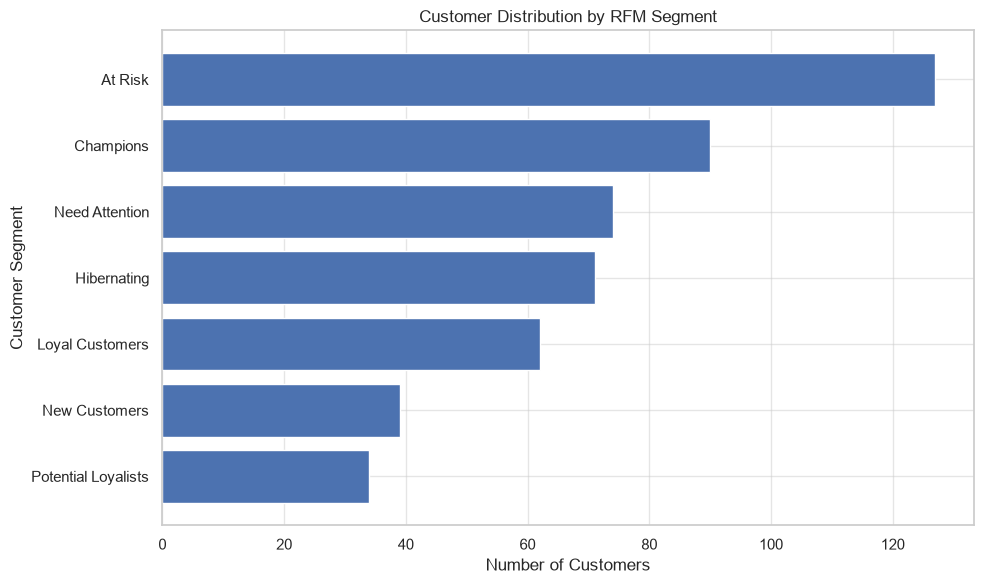

,customer_segment,customer_count,customer_percentage
0,At Risk,127,25.55
1,Champions,90,18.11
2,Need Attention,74,14.89
3,Hibernating,71,14.29
4,Loyal Customers,62,12.47
5,New Customers,39,7.85
6,Potential Loyalists,34,6.84


In [22]:
plot_data = segment_counts.sort_values("customer_count", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(plot_data["customer_segment"], plot_data["customer_count"])
plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.savefig(CHARTS / "01_customer_distribution_by_segment.png", dpi=200)
plt.show()
display(segment_counts.sort_values("customer_count", ascending=False))

## 3. Revenue contribution by customer segment

We aggregate Monetary value for each segment. This helps distinguish segments with many customers from segments that contribute more revenue.

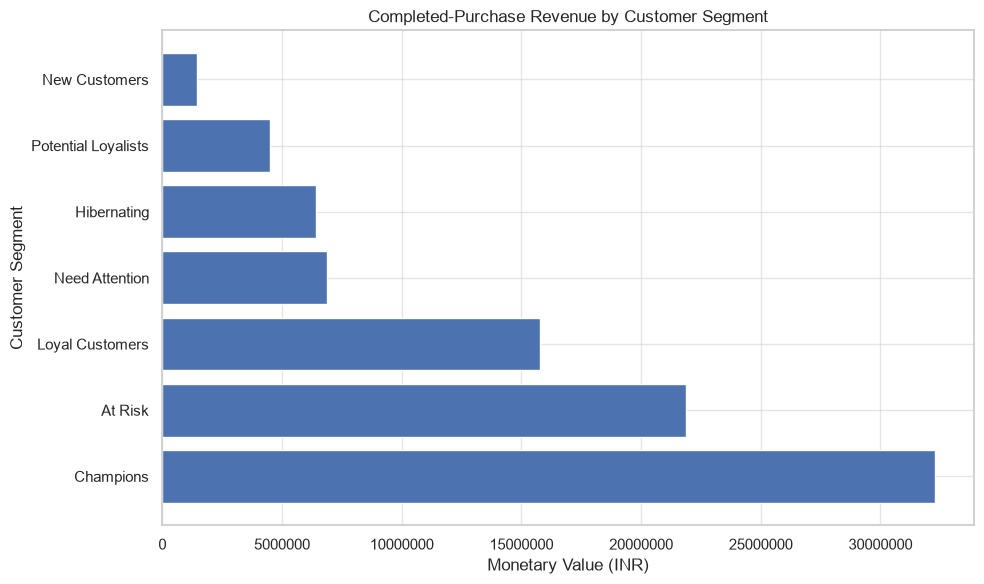

,customer_segment,monetary
1,Champions,32291583.15
0,At Risk,21872105.92
3,Loyal Customers,15766704.64
4,Need Attention,6889331.09
2,Hibernating,6425529.63
6,Potential Loyalists,4476486.01
5,New Customers,1446145.26


In [23]:
revenue_segment = (rfm.groupby("customer_segment", as_index=False)["monetary"]
                   .sum().sort_values("monetary", ascending=False))
plt.figure(figsize=(10, 6))
plt.barh(revenue_segment["customer_segment"], revenue_segment["monetary"])
plt.title("Completed-Purchase Revenue by Customer Segment")
plt.xlabel("Monetary Value (INR)")
plt.ylabel("Customer Segment")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.savefig(CHARTS / "02_revenue_by_segment.png", dpi=200)
plt.show()
display(revenue_segment)

## 4. Top 10 customers by Monetary value

These are the ten customers with the highest completed-purchase monetary value in the P8 result.

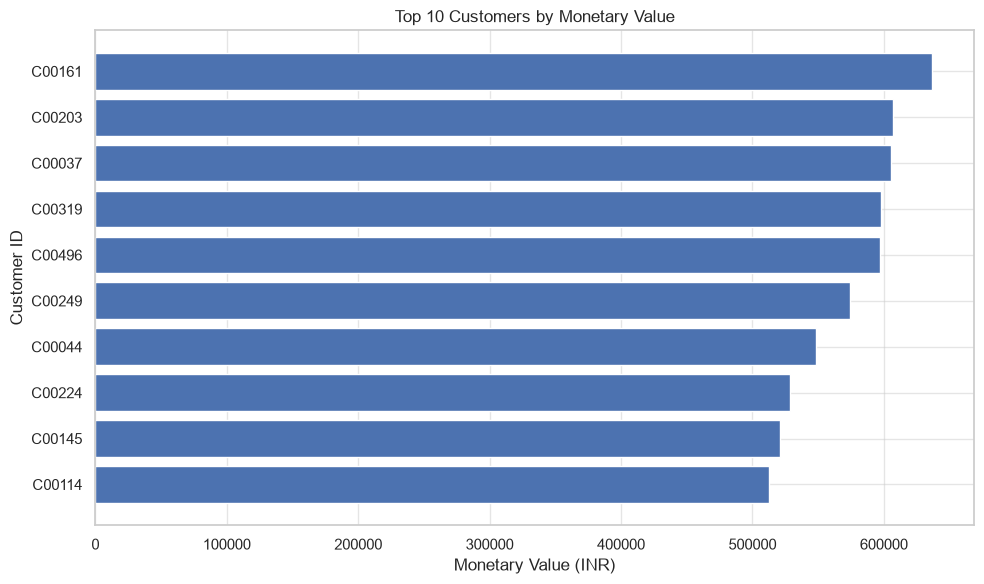

,customer_id,city,state,frequency,monetary
0,C00161,Hyderabad,Telangana,28,636717.70
1,C00203,Hyderabad,Telangana,25,606557.81
2,C00037,Pune,Maharashtra,26,605064.44
3,C00319,Ahmedabad,Gujarat,26,598005.68
4,C00496,Indore,Madhya Pradesh,27,597353.09
5,C00249,Ahmedabad,Gujarat,26,574324.29
6,C00044,Lucknow,Uttar Pradesh,26,548067.94
7,C00224,Mumbai,Maharashtra,28,528242.40
8,C00145,Ahmedabad,Gujarat,22,520978.98
9,C00114,Kochi,Kerala,26,512306.07


In [24]:
top_plot = top10.sort_values("monetary", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(top_plot["customer_id"], top_plot["monetary"])
plt.title("Top 10 Customers by Monetary Value")
plt.xlabel("Monetary Value (INR)")
plt.ylabel("Customer ID")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.savefig(CHARTS / "03_top_10_customers.png", dpi=200)
plt.show()
display(top10)

## 6. Recency distribution

Recency is measured in days. A smaller value means the customer purchased more recently. The box plot helps inspect the spread and possible extreme values.

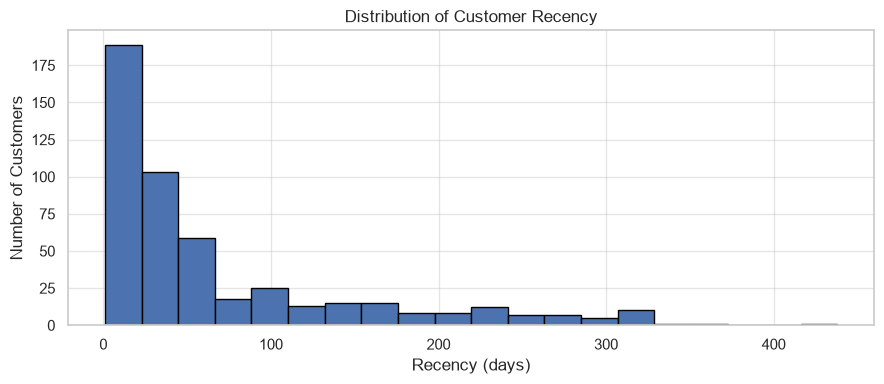

C:\Users\Priyanshu\AppData\Local\Temp\ipykernel_2032\1111884496.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(rfm["recency_days"], vert=False)


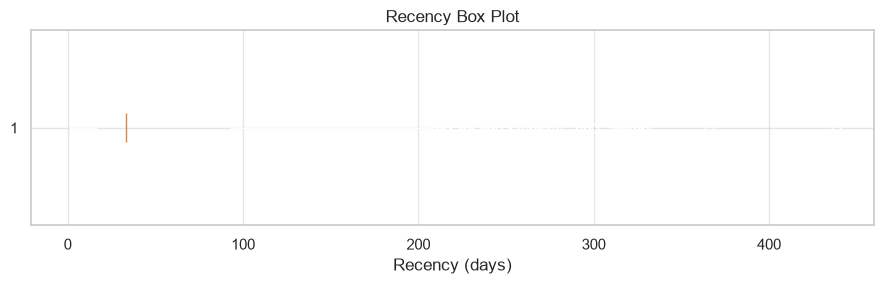

In [25]:
plt.figure(figsize=(9, 4))
plt.hist(rfm["recency_days"], bins=20, edgecolor="black")
plt.title("Distribution of Customer Recency")
plt.xlabel("Recency (days)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(CHARTS / "04_recency_distribution.png", dpi=200)
plt.show()

plt.figure(figsize=(9, 3))
plt.boxplot(rfm["recency_days"], vert=False)
plt.title("Recency Box Plot")
plt.xlabel("Recency (days)")
plt.tight_layout()
plt.savefig(CHARTS / "05_recency_boxplot.png", dpi=200)
plt.show()

## 6. Frequency distribution

Frequency counts distinct completed invoices per customer, not individual product rows.

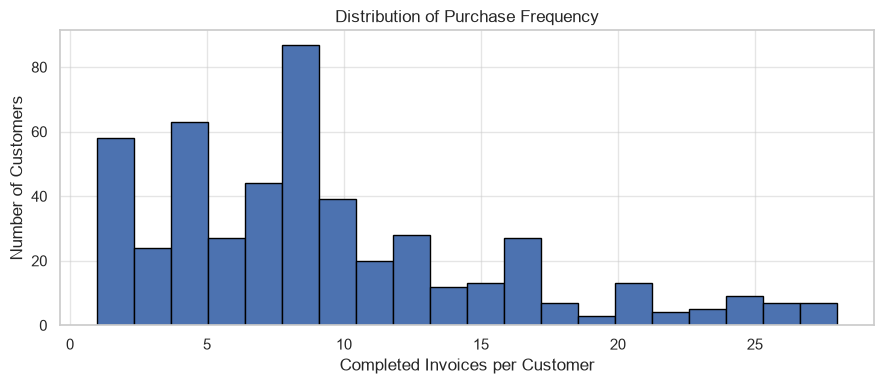

In [26]:
plt.figure(figsize=(9, 4))
plt.hist(rfm["frequency"], bins=20, edgecolor="black")
plt.title("Distribution of Purchase Frequency")
plt.xlabel("Completed Invoices per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(CHARTS / "06_frequency_distribution.png", dpi=200)
plt.show()

## 8. Monetary value distribution

Monetary represents the total net value of completed purchases after discounts. Values are in Indian Rupees (INR).

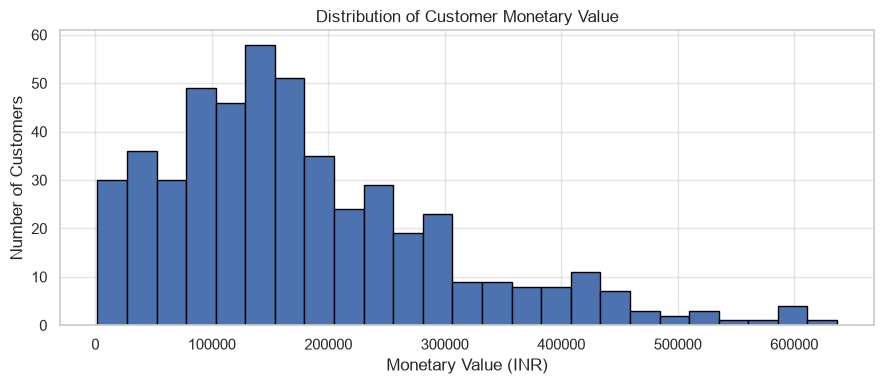

In [27]:
plt.figure(figsize=(9, 4))
plt.hist(rfm["monetary"], bins=25, edgecolor="black")
plt.title("Distribution of Customer Monetary Value")
plt.xlabel("Monetary Value (INR)")
plt.ylabel("Number of Customers")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.savefig(CHARTS / "07_monetary_distribution.png", dpi=200)
plt.show()

## 9. Revenue by product category

Compare the net revenue generated by each product category. Revenue is based on completed orders.

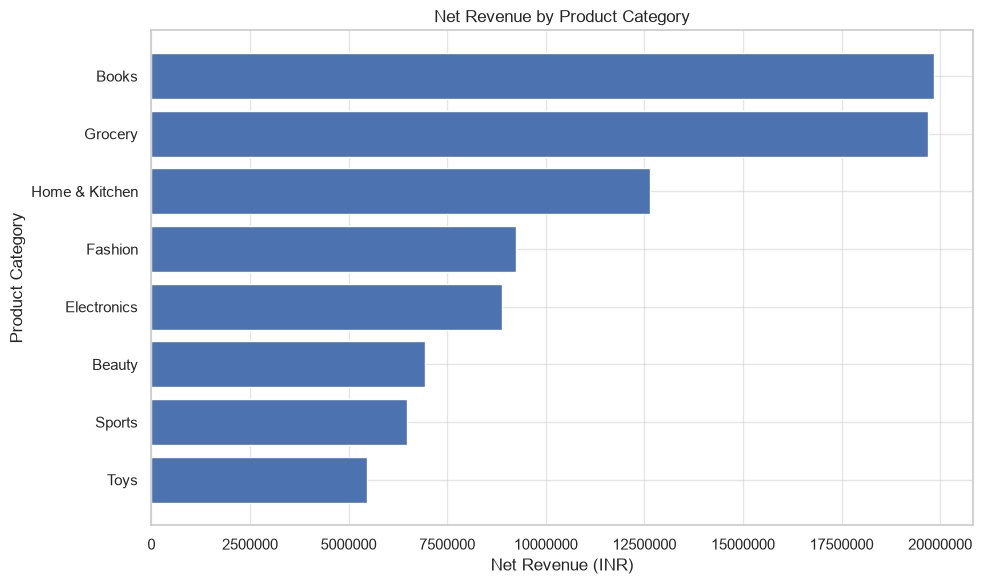

,category,invoice_count,units_sold,net_revenue
0,Books,1651,4691,19843950.83
1,Grocery,1691,4880,19680700.56
2,Home & Kitchen,980,2607,12649191.03
3,Fashion,1072,2916,9235990.34
4,Electronics,960,2632,8879863.24
5,Beauty,833,2199,6932104.35
6,Sports,756,1998,6483264.00
7,Toys,460,1175,5462821.37


In [28]:
category_plot = category.sort_values("net_revenue", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(category_plot["category"], category_plot["net_revenue"])
plt.title("Net Revenue by Product Category")
plt.xlabel("Net Revenue (INR)")
plt.ylabel("Product Category")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.savefig(CHARTS / "08_revenue_by_category.png", dpi=200)
plt.show()
display(category.sort_values("net_revenue", ascending=False))

## 10. Monthly revenue trend

The line chart shows monthly completed-purchase revenue from January 2025 to October 2026.

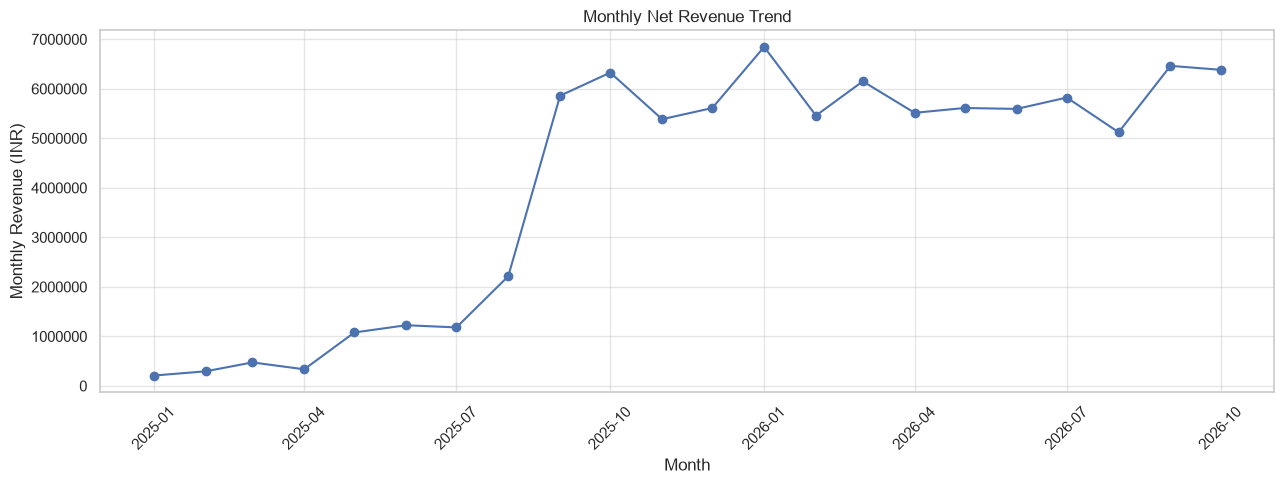

In [29]:
monthly["sales_month"] = pd.to_datetime(monthly["sales_month"])
monthly = monthly.sort_values("sales_month")
plt.figure(figsize=(13, 5))
plt.plot(monthly["sales_month"], monthly["monthly_revenue"], marker="o")
plt.title("Monthly Net Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Monthly Revenue (INR)")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.savefig(CHARTS / "09_monthly_revenue_trend.png", dpi=200)
plt.show()

## 12. Revenue by acquisition channel

Aggregate customer Monetary value by acquisition channel. This is descriptive and does not establish that a channel caused higher spending.

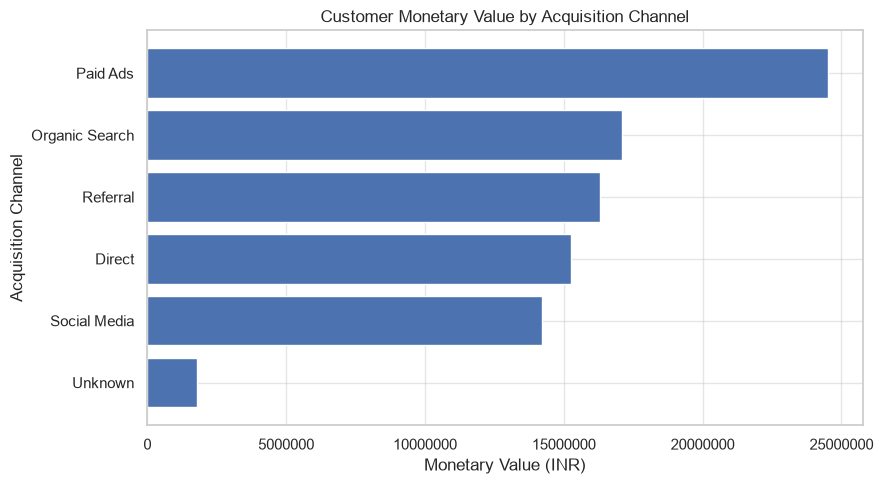

,acquisition_channel,monetary
5,Unknown,1787868.43
4,Social Media,14208775.37
0,Direct,15254842.36
3,Referral,16305556.04
1,Organic Search,17078648.66
2,Paid Ads,24532194.84


In [30]:
channel_revenue = (rfm.groupby("acquisition_channel", as_index=False)["monetary"]
                  .sum().sort_values("monetary", ascending=True))
plt.figure(figsize=(9, 5))
plt.barh(channel_revenue["acquisition_channel"], channel_revenue["monetary"])
plt.title("Customer Monetary Value by Acquisition Channel")
plt.xlabel("Monetary Value (INR)")
plt.ylabel("Acquisition Channel")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.savefig(CHARTS / "10_revenue_by_acquisition_channel.png", dpi=200)
plt.show()
display(channel_revenue)

## 11. Compare R, F and M scores

The score distribution shows how the quintile scoring divides customers across scores 1–5. For Recency, a higher score means a more recent purchase. For Frequency and Monetary, a higher score means a higher value.

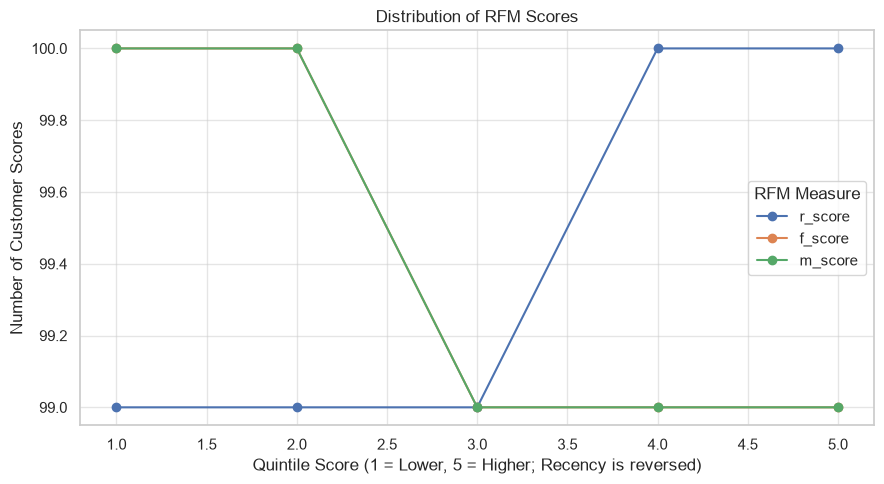

In [31]:
score_summary = rfm[["r_score", "f_score", "m_score"]].melt(
    var_name="RFM Measure", value_name="Score"
)
plt.figure(figsize=(9, 5))
for measure in ["r_score", "f_score", "m_score"]:
    counts = rfm[measure].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
    plt.plot(counts.index, counts.values, marker="o", label=measure)
plt.legend(title="RFM Measure")
plt.title("Distribution of RFM Scores")
plt.xlabel("Quintile Score (1 = Lower, 5 = Higher; Recency is reversed)")
plt.ylabel("Number of Customer Scores")
plt.tight_layout()
plt.savefig(CHARTS / "11_rfm_score_comparison.png", dpi=200)
plt.show()

## 14. RFM relationship heatmap

The correlation matrix shows linear association between Recency, Frequency and Monetary. Correlation does not prove causation.

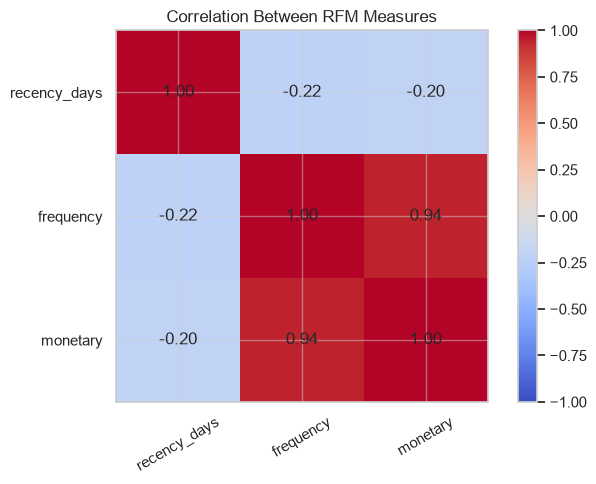

In [32]:
corr = rfm[["recency_days", "frequency", "monetary"]].corr()
plt.figure(figsize=(7, 5))
image = plt.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(image)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=30)
plt.yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Correlation Between RFM Measures")
plt.tight_layout()
plt.savefig(CHARTS / "12_rfm_correlation_heatmap.png", dpi=200)
plt.show()

## 15. Month-over-month revenue movement

This uses the P8 SQL result calculated with `LAG()`. The first month has no previous month for comparison.

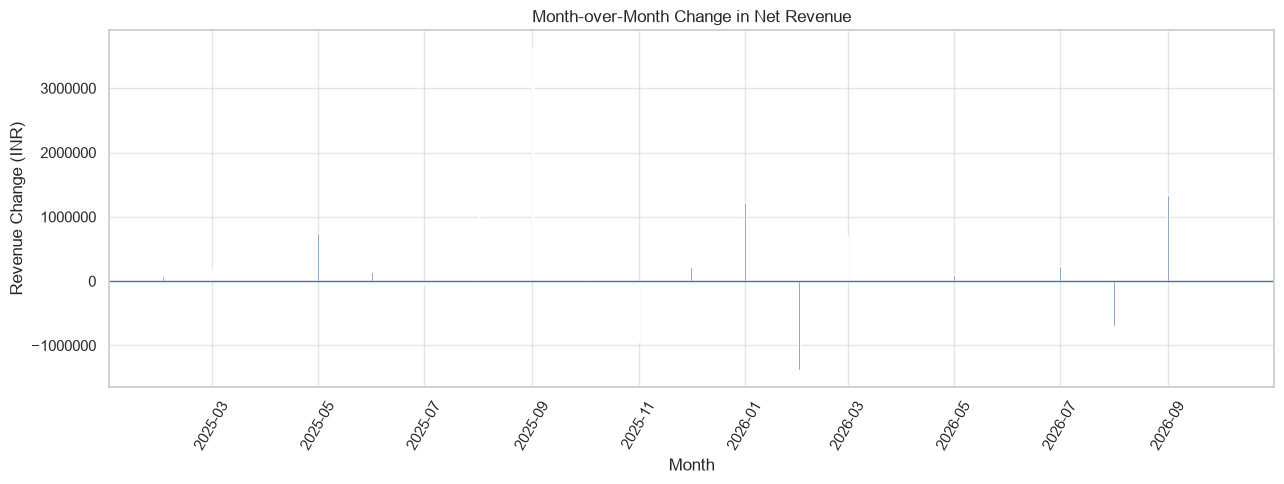

,sales_month,monthly_revenue,previous_month_revenue,revenue_change,revenue_movement
16,2026-05-01,5612958.80,5515198.91,97759.90,Growth
17,2026-06-01,5593957.79,5612958.80,-19001.01,Decline
18,2026-07-01,5823458.39,5593957.79,229500.60,Growth
19,2026-08-01,5122369.07,5823458.39,-701089.33,Decline
20,2026-09-01,6463341.15,5122369.07,1340972.08,Growth
21,2026-10-01,6383950.81,6463341.15,-79390.34,Decline


In [33]:
monthly_lag["sales_month"] = pd.to_datetime(monthly_lag["sales_month"])
monthly_lag = monthly_lag.sort_values("sales_month")
plt.figure(figsize=(13, 5))
plt.bar(monthly_lag.dropna(subset=["revenue_change"])["sales_month"], monthly_lag.dropna(subset=["revenue_change"])["revenue_change"])
plt.axhline(0, linewidth=1)
plt.title("Month-over-Month Change in Net Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue Change (INR)")
plt.xticks(rotation=60)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.savefig(CHARTS / "13_month_over_month_change.png", dpi=200)
plt.show()
display(monthly_lag.tail(6))

## 16. Key findings from the generated dataset

Use the actual results below rather than assuming that every segment has equal value.

In [34]:
largest_segment = segment_counts.loc[segment_counts["customer_count"].idxmax()]
top_category = category.loc[category["net_revenue"].idxmax()]
top_month = monthly.loc[monthly["monthly_revenue"].idxmax()]
top_channel = channel_revenue.loc[channel_revenue["monetary"].idxmax()]

print(f"RFM customers analysed: {rfm['customer_id'].nunique()}")
print(f"Largest segment: {largest_segment['customer_segment']} ({int(largest_segment['customer_count'])} customers; {largest_segment['customer_percentage']:.2f}%)")
print(f"Highest-revenue category: {top_category['category']} (INR {top_category['net_revenue']:,.2f})")
print(f"Highest-revenue month: {top_month['sales_month'].strftime('%Y-%m')} (INR {top_month['monthly_revenue']:,.2f})")
print(f"Highest Monetary acquisition channel: {top_channel['acquisition_channel']} (INR {top_channel['monetary']:,.2f})")
print("\nInterpretation caution: These findings describe this synthetic dataset only. They are not evidence about a real retailer or real customers.")

RFM customers analysed: 497
Largest segment: At Risk (127 customers; 25.55%)
Highest-revenue category: Books (INR 19,843,950.83)
Highest-revenue month: 2026-01 (INR 6,846,436.99)
Highest Monetary acquisition channel: Paid Ads (INR 24,532,194.84)

Interpretation caution: These findings describe this synthetic dataset only. They are not evidence about a real retailer or real customers.


## 17. Export analysis tables

Save the aggregated tables used in this notebook so they can be reused in reports or Power BI.

In [35]:
revenue_segment.to_csv(PROJECT_ROOT / "outputs" / "p9_revenue_by_segment.csv", index=False)
channel_revenue.to_csv(PROJECT_ROOT / "outputs" / "p9_revenue_by_acquisition_channel.csv", index=False)
score_summary.to_csv(PROJECT_ROOT / "outputs" / "p9_rfm_score_distribution.csv", index=False)
print("Analysis tables and charts exported successfully.")

Analysis tables and charts exported successfully.


## Conclusion

This notebook completed descriptive analysis of the RFM customer dataset. It visualized segment distribution, customer value, RFM measure distributions, category and monthly revenue, acquisition channels, score distribution and RFM correlations.

**Limitations:** The dataset is synthetic. RFM segments are rule-based classifications from quintile scores. Results should not be generalized to a real business without validating the definitions and using real transaction data.